# 04 — Competitors: Latest Physical World Models vs Ours

Recency-biased landscape (sweep of arXiv/OpenReview/HF/lab pages; see `notebooks/competitors_data.json` for the sourced rows, one URL per row). Motivation frame: large-qubit fault-tolerant machines are decades out — the question is whether a *hybrid* qubit+world-model gives better analog-like physical simulation **today** than world models alone, with a native export path to analog hardware.

In [1]:
import sys, pathlib, glob, re, warnings
warnings.filterwarnings('ignore')
ROOT = pathlib.Path().resolve().parent
sys.path.insert(0, str(ROOT / 'paper'))
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 90
DEVICE = 'cpu'   # GPU reserved for the sprint queue; flip when free
torch.manual_seed(0)


In [2]:
import json
data = json.load(open(ROOT / 'notebooks/competitors_data.json'))
comp = pd.DataFrame(data['rows'])
print(f"sweep date: {data['sweep_date']}, rows: {len(comp)}")
comp.sort_values('date', ascending=False).reset_index(drop=True)

sweep date: 2026-08-15, rows: 33


,model,org,date,benchmark,metric,score,params,physics_mechanism,id
0,Kandinsky-WM 1.0,Sber AI,2026-08-04,Physics-IQ Verified,"i2v score 0-100 (newest entry, Aug 2026)",30.8 ± 0.9,,Video world model,github.com/google-deepmind/physics-IQ-benchmar...
1,Cosmos3-Super,NVIDIA,2026-06-22,"Physics-IQ (original, self-run) + PAIBench-G +...","Physics-IQ 0-100 (I2V/V2V, direct and +WMRewar...",Physics-IQ I2V 43.8 → 48.9 BoN; V2V 59.7 → 63....,,Omnimodal (video+audio+text) world model for P...,"arXiv:2606.02800 (Tables 13, 32) — https://arx..."
2,Magi-1 24B + GeoPhys (BoN),Sand AI (+GeoPhys reranker),2026-06-19,Physics-IQ Verified,"Physics-IQ Verified score 0-100, v2v (3s condi...",58.2 ± 1.8 (rank 1),24B,Autoregressive chunked video diffusion + geome...,github.com/google-deepmind/physics-IQ-benchmar...
3,Magi-1 24B + GeoPhys (BoN),Sand AI,2026-06-19,Physics-IQ Verified,i2v score 0-100 (next: Hunyuan 1.5 33.4; Wan2....,33.7 ± 1.4 (rank 5),24B,"As above, i2v mode",github.com/google-deepmind/physics-IQ-benchmar...
4,Magi-1 24B,Sand AI,2026-06-19,Physics-IQ Verified,v2v score 0-100,48.4 ± 1.1 (rank 2),24B,Autoregressive chunked video diffusion,github.com/google-deepmind/physics-IQ-benchmar...
5,Cosmos3-Super-Image2Video,NVIDIA,2026-06-18,Physics-IQ Verified,i2v score 0-100,39.5 ± 0.8 (rank 3; best i2v),,Omnimodal diffusion world model,github.com/google-deepmind/physics-IQ-benchmar...
6,Magi-1 + GeoPhys (BoN),Sand AI,2026-06-17,Physics-IQ (original protocol),"Physics-IQ score 0-100 %, v2v",64.5% (rank 1; original-protocol leaderboard),24B,Physics-steered BoN reranking,github.com/google-deepmind/physics-IQ-benchmar...
7,Grok Imagine Video,xAI,2026-06-17,Physics-IQ Verified,i2v score 0-100,34.8 ± 0.6 (rank 4),,Closed video generation,github.com/google-deepmind/physics-IQ-benchmar...
8,WaveLiT-S,(DOE ASCR-funded; NeurIPS 2025 ML4PS),2025-12,The Well turbulent_radiative_layer_2D,1-step VRMSE ('consistent with baselines repor...,0.1755 (1-step); 0.687 (6:12),1.2M,Discrete-wavelet tokenization + MLLA linear at...,NeurIPS_ML4PS_2025_203 — https://ml4physicalsc...
9,WaveLiT-B,(NeurIPS 2025 ML4PS),2025-12,The Well turbulent_radiative_layer_2D,1-step VRMSE; rollout 6:12,0.1346 (1-step); 0.562 (6:12),9M,Same; 31.2% better than CNextU-net on TRL2D,NeurIPS_ML4PS_2025_203


## The Well TRL2D — the directly comparable arena

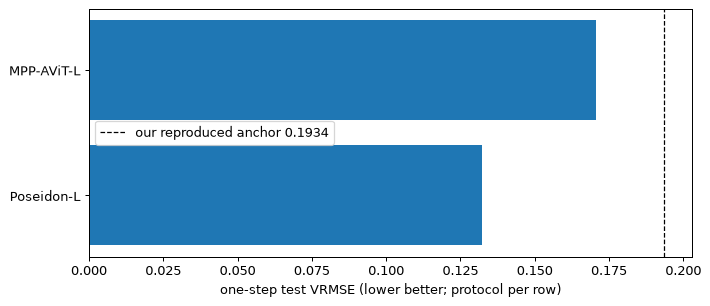

     model params                                 metric  score
Poseidon-L  ~629M MEDIAN VRMSE, 1-step (Walrus protocol) 0.1323
MPP-AViT-L  ~409M MEDIAN VRMSE, 1-step (Walrus protocol) 0.1707


In [3]:
well = comp[comp['benchmark'].str.contains('turbulent_radiative', case=False)]
well = well.copy()
well['score_f'] = pd.to_numeric(well['score'], errors='coerce')
well = well.dropna(subset=['score_f']).sort_values('score_f')
fig, ax = plt.subplots(figsize=(8, 3.5))
colors = ['tab:red' if 'ours' in m.lower() else 'tab:blue' for m in well['model']]
ax.barh(well['model'], well['score_f'], color=colors)
ax.axvline(0.1934, ls='--', c='k', lw=1, label='our reproduced anchor 0.1934')
ax.set_xlabel('one-step test VRMSE (lower better; protocol per row)')
ax.legend(); plt.tight_layout(); plt.show()
print(well[['model','params','metric','score']].to_string(index=False))

## Mechanism comparison — how each model 'does physics'

In [4]:
mech = comp.dropna(subset=['physics_mechanism']) if 'physics_mechanism' in comp else comp
for _, r in mech.iterrows():
    if r.get('physics_mechanism'):
        print(f"{r['model']:22s} | {str(r.get('params','?')):>8s} | {r['physics_mechanism'][:90]}")
print()
print('OURS: input-conditioned Rydberg-Hamiltonian bottleneck (~500-2k quantum')
print('params) inside frozen SOTA backbones; physics via learned analog dynamics')
print('+ pre-registered invariant/rollout evaluation; Pulser-exportable.')

FNO                    |          | Fourier neural operator (global spectral modes)
TFNO                   |          | Tucker-factorized FNO
U-Net                  |          | Convolutional encoder-decoder
CNextU-net  ← OUR TARGET |          | U-Net with ConvNeXt blocks
FNO                    |          | Fourier neural operator
TFNO                   |          | Tucker-factorized FNO
U-Net                  |          | Convolutional encoder-decoder
CNextU-net             |          | U-Net with ConvNeXt blocks
Walrus                 |     1.3B | Cross-domain transformer foundation model, 2D+3D unified, trajectory-jitter stabilization 
Walrus                 |     1.3B | Same as above; only 3D-capable FM in its comparison besides DPOT
MPP-AViT-L             |    ~409M | Axial ViT, multi-physics pretraining
Poseidon-L             |    ~629M | Scalable operator transformer (scOT), all2all time conditioning
DPOT-H                 |   ~1.03B | Denoising-pretrained Fourier transformer
Wa

## Where we sit
- **Scale axis**: competitors push parameters (1.3B-64B); our delta is a ~1.5M-param adapter on a frozen backbone — the efficiency end of the frontier, reproducible on one 126 GB desktop.
- **Mechanism axis**: published physics mechanisms are architectural priors, data scale, or losses; none couples to an analog-hardware-native dynamical system. That slot (audit C5/C1) is ours.
- **Evaluation axis**: rollout collapse past ~13 steps remains universal (incl. 1.3B Walrus) — long-horizon stability is the open flank our quantum arms attack.
- **Risk**: the field moves ~1 relevant paper/month (audit 09); re-run this sweep before submission.